[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zakariae-lazraq/ai-agents-healthcare-labs/blob/main/notebooks/Lab07_Research_Agent.ipynb)

# Lab 7: A research agent with verified citations
**AI Agents for Healthcare and Diagnostics** · Module 6 · about 75 minutes

**The situation.** Northbridge scientists want quick evidence summaries: a method comparison, a biomarker, a
companion diagnostic. An agent can search PubMed and read abstracts in seconds, but a summary is only useful if
**every claim points to a real article that supports it**, and if the agent says "no evidence" when there is none.

**At the end of this lab you will be able to:**
- build an agent that searches PubMed, reads abstracts and writes a summary where every sentence has a PMID;
- check its citations with the Lab 6 guardian: does the PMID exist, was it retrieved, does it support the claim?
- verify three citations yourself, and compare with Gemini Deep Research;
- test the agent on a biomarker that does not exist.

| Word | Meaning here |
|---|---|
| **PMID** | the PubMed identifier of an article: click it to read the abstract |
| **Retrieved** | the agent fetched and read this article's abstract with its tools in this session (found in a search is not enough) |
| **Publication type** | PubMed's label: meta-analysis / systematic review > trial > observational > review. A rough proxy only: real appraisal of diagnostic evidence uses QUADAS-2 (risk of bias), GRADE (certainty) and, for method comparison, CLSI EP09 |
| **Word overlap** | the guardian's automatic check: how much of a sentence's vocabulary and numbers appear in the abstract: high / medium / low, not "true" |

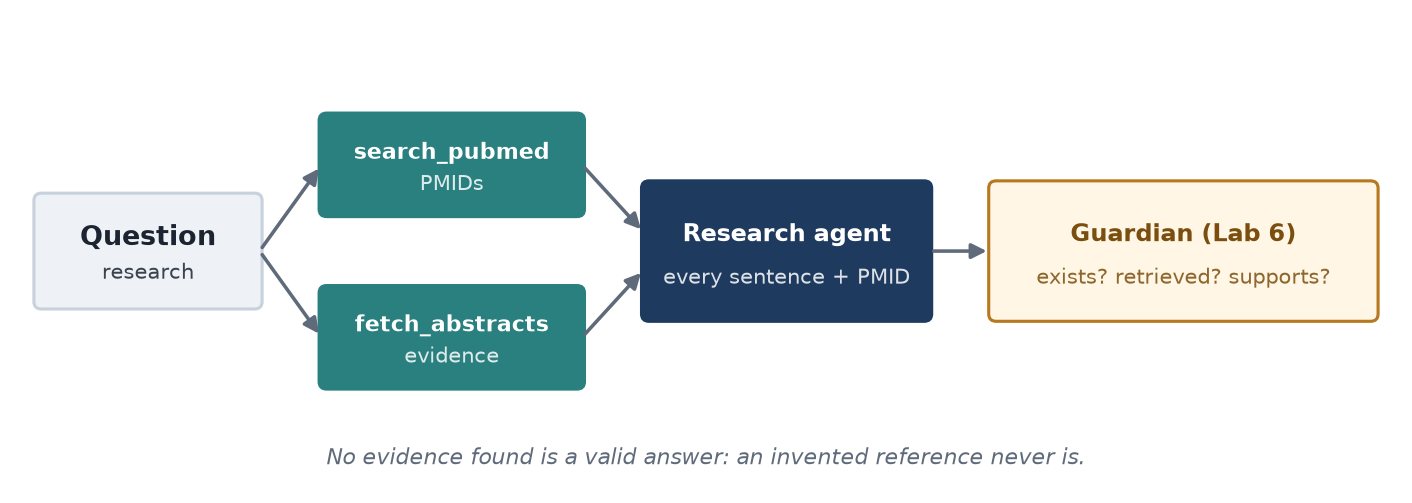

*The agent searches and reads; the guardian checks every PMID before you trust the summary.*

### Setup: run this cell (about 1 minute)
Same as in Lab 0: it installs the course tools, downloads the course files and checks your key. The code is folded: just run it.

In [ ]:
# @title Setup (click run and wait about 1 minute)
import os, subprocess, sys
REPO = "https://github.com/zakariae-lazraq/ai-agents-healthcare-labs"
MODEL = "gemini-3.5-flash-lite"  # @param {type:"string"}
___ = "___"  # the blank you will replace in YOUR CELL

def _step(what, cmd):
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(f"FAILED: {what}. Run this cell again; if it fails twice, send the text below to the trainer:")
        print((r.stderr or r.stdout)[-800:])
        return False
    print(f"done: {what}")
    return True

try:
    import google.colab  # noqa: F401  (present only inside Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

_ready = True
if IN_COLAB:
    if not os.path.exists("/content/course"):
        _ready = _step("download course files", ["git", "clone", "-q", "--depth", "1", REPO, "/content/course"])
    if _ready:
        _ready = _step("install Google ADK", [sys.executable, "-m", "pip", "install", "-q", "google-adk==2.15.0"])
    sys.path.insert(0, "/content/course")

SETUP_OK, SETUP_RESULTS = False, []
if _ready:
    from google.adk.agents import Agent
    from labkit.setup import check_environment, show_checks
    from labkit.agents import make_model, run, DETERMINISTIC
    from labkit.ui import check, has_blank, ready, copy_box, done_card
    import json
    import pandas as pd
    from IPython.display import HTML, display
    from labkit import DATA_DIR
    from labkit import research
    from labkit.audit import AuditLog
    from labkit.ui import error_line
    LAB = DATA_DIR / "lab07"
    NCBI_EMAIL = ""  # optional: NCBI asks automated tools for a contact e-mail; leave empty in class
    PUBMED = research.PubMedClient(LAB / "pubmed_cache.json", live=True, email=NCBI_EMAIL)   # live NCBI, cached copy if offline
    QUESTIONS = {q["id"]: q for q in json.loads((LAB / "questions.json").read_text(encoding="utf-8"))}
    _t = research.make_research_tools(PUBMED)
    search_pubmed, fetch_abstracts, verify_claim = _t["search_pubmed"], _t["fetch_abstracts"], _t["verify_claim"]
    LOG = AuditLog()
    SETUP_RESULTS = check_environment(MODEL, ping_pubmed=False)
    SETUP_OK = show_checks(SETUP_RESULTS)

**What you should see:** every line marked **OK**, then *"Everything is ready"*. Same Setup as Lab 0.

**If it does not work**

| You see | Do this |
|---|---|
| FIX: API key found | Open Secrets (key icon, left sidebar): `GOOGLE_API_KEY`, *Notebook access* on; run Setup again |
| FIX: API key works, "busy" or "quota" | Wait 30–60 seconds, run Setup again |
| FAILED: download / install | Run Setup again; if it fails twice, send the text to the trainer |
| `NameError: ... is not defined` in later cells | Session restarted: click the cell, then **Runtime → Run before** |

## Part 1: Gemini Deep Research (about 15 minutes, Track A)
The research questions of this lab:

In [ ]:
# @title The research questions (run this cell)
for _q in QUESTIONS.values():
    if _q["id"] != "TRAP":
        display(copy_box(_q["question"], f"{_q['id']}: {_q['kind']}"))

### Task 1: Check three citations of a Deep Research report
<sub>IN THE GEMINI APP · ABOUT 15 MIN</sub>

**Your task.** See how a powerful research tool cites, and verify it the way a reviewer would.

**Steps**

1. In the Gemini app, run **Deep Research** on question R2 (troponin). It takes a few minutes: start it, continue the lab, come back.
2. Pick three references from the report. Open each one (PubMed or the publisher) and check: does it exist, and does it say what the report claims?
3. Record your result in the form, then run the cell and the CHECK. (Optional: put the sources into a **Gemini Notebook** and ask for a data table of study design, population and main result.)

In [ ]:
# @title Your check of three Deep Research citations
# YOUR CELL: fill in the form on the right, then run this cell
citations_supported = "choose…"  # @param ["choose…", "3 of 3", "2 of 3", "1 of 3", "0 of 3", "Deep Research not available to me"]
fake_or_broken = "choose…"  # @param ["choose…", "none", "at least one did not exist or did not open", "at least one existed but said something else"]

In [ ]:
# @title CHECK (run this cell): it tells you what is right and what to fix
_ok = check([(citations_supported != "choose…" and fake_or_broken != "choose…", "Result recorded",
              "Choose an option in both fields.")])
if _ok:
    DEEP_RESEARCH = (citations_supported, fake_or_broken)

<details><summary><b>Hint</b>: open only if you are stuck</summary>

Read the abstract, not only the title: the question is whether the source supports the specific sentence. Deep Research often cites web pages too: what makes a source trustworthy for your lab?

</details>

## Part 2: Build the research agent (about 45 minutes)
The tools call NCBI's E-utilities (the official PubMed API); if PubMed cannot be reached, they fall back to a
copy shipped with the course and say so. Try one:

In [ ]:
search_pubmed("high-sensitivity troponin rule-out myocardial infarction", 3)

### Task 2: Write the research agent's instruction
<sub>IN THE NOTEBOOK · ABOUT 8 MIN</sub>

**Your task.** Make citation discipline part of the agent's job, not an afterthought.

**Steps**

1. **Search and read:** call search_pubmed (one or two queries), then fetch_abstracts.
2. **Cite every sentence:** 4–6 sentences, each ending with `(PMID …)` of a retrieved article that supports it.
3. **Never invent:** no reference or number that is not in the abstracts.
4. **Say when evidence is missing:** *No evidence was found in PubMed for this.*
5. **Fixed ending:** `EVIDENCE STRENGTH: strong / moderate / weak / none`. Run your cell and the CHECK.

In [ ]:
# YOUR CELL: replace every ___ , then run this cell
RESEARCH_INSTRUCTION = """___"""

In [ ]:
# @title CHECK (run this cell): it tells you what is right and what to fix
_i = RESEARCH_INSTRUCTION.lower()
_blank = has_blank(RESEARCH_INSTRUCTION)
_ok = check([(False, "Instruction written", _blank)]) if _blank else check([
    ("search_pubmed" in _i and "fetch_abstracts" in _i, "Uses both tools", "Name search_pubmed and fetch_abstracts."),
    ("pmid" in _i and ("every sentence" in _i or "each sentence" in _i), "Every sentence cites a PMID",
     "Write: every sentence must end with (PMID …)."),
    ("never" in _i and ("invent" in _i or "did not retrieve" in _i), "Never invents references",
     "Write: never cite an article you did not retrieve; never invent a reference."),
    ("no evidence" in _i, "Says when evidence is missing", "Give it the words: No evidence was found in PubMed."),
    ("evidence strength:" in _i, "Fixed ending", "End with: EVIDENCE STRENGTH: strong / moderate / weak / none."),
])

<details><summary><b>Hint</b>: open only if you are stuck</summary>

The same discipline as the SOP agent of Lab 1, applied to literature: the sources are what the tools retrieved in this session: nothing else.

</details>

In [ ]:
# @title Build the agent and ask a research question (choose, then run)
question = "R2"  # @param ["R1", "R2", "R3"]
RTOOLS = [search_pubmed, fetch_abstracts]
if ready("research_agent", RESEARCH_INSTRUCTION, RTOOLS, example="search_pubmed"):
    research_agent = Agent(name="research_agent", model=make_model(MODEL), instruction=RESEARCH_INSTRUCTION,
                           tools=RTOOLS, generate_content_config=DETERMINISTIC, after_tool_callback=LOG.callback)
    PUBMED.retrieved.clear()
    SUMMARY = run(research_agent, QUESTIONS[question]["question"]).text
else:
    research_agent = None

In [ ]:
# @title The guardian checks every citation (Lab 6): run this cell
if not globals().get("SUMMARY"):
    display(error_line("Run the research agent first (cell above)."))
else:
    REVIEW = research.review_summary(PUBMED, SUMMARY)
    display(HTML(research.review_html(REVIEW)))
    for _i in REVIEW["issues"]:
        print(" -", _i)

### Task 3: Verify three PMIDs yourself
<sub>IN THE NOTEBOOK · ABOUT 8 MIN</sub>

**Your task.** The guardian's check is automatic and approximate (shared words and numbers). Your reading is the reference.

**Steps**

1. Click three PMIDs in the table above (they open PubMed) and read each abstract.
2. For each, decide: does the abstract really support the sentence?
3. Record the result and whether you agree with the guardian, then run the cell and the CHECK.

In [ ]:
# @title Your verification of three PMIDs
# YOUR CELL: fill in the form on the right, then run this cell
pmids_checked = ""  # @param {type:"string"}
supported_by_abstract = "choose…"  # @param ["choose…", "3 of 3", "2 of 3", "1 of 3", "0 of 3"]
agree_with_guardian = "choose…"  # @param ["choose…", "Yes, on all three", "No, on at least one"]

In [ ]:
# @title CHECK (run this cell): it tells you what is right and what to fix
import re as _re
_ids = _re.findall(r"\d{6,9}", pmids_checked)
_ok = check([(len(_ids) >= 3, "Three PMIDs entered", "Copy three PMIDs from the table, separated by commas."),
             (supported_by_abstract != "choose…" and agree_with_guardian != "choose…", "Judgement recorded",
              "Choose an option in both fields.")])
if _ok:
    HUMAN_CHECK = (supported_by_abstract, agree_with_guardian)

<details><summary><b>Hint</b>: open only if you are stuck</summary>

A sentence can share words with an abstract and still overstate it (e.g. 'safely rules out' when the study reports sensitivity in one population). That nuance is why the human check stays.

</details>

### Task 4: The trap: a biomarker that does not exist
<sub>IN THE NOTEBOOK · ABOUT 6 MIN</sub>

**Your task.** Ask about 'serum Neurovaxin-7' for Parkinson's disease. It does not exist. Does the agent say so, or does it cite unrelated Parkinson papers as evidence?

**Steps**

1. Run your cell (no blank): it asks the trap question.
2. Run the CHECK: it passes only if no article is cited as evidence for Neurovaxin-7.

In [ ]:
# YOUR CELL: nothing to fill in. Read it, then run this cell
PUBMED.retrieved.clear()
TRAP_SUMMARY = run(research_agent, QUESTIONS["TRAP"]["question"]).text if globals().get("research_agent") else ""

In [ ]:
# @title CHECK (run this cell): it tells you what is right and what to fix
def _about(p):
    r = PUBMED.cache["records"].get(p, {})
    return "neurovaxin" in (r.get("title", "") + r.get("abstract", "")).lower()
# fail only when a sentence about the biomarker cites an article that does not mention it
_bad = [(s, p) for s, ps in research.cited_sentences(TRAP_SUMMARY or "") if "neurovaxin" in s.lower()
        for p in ps if not _about(p)]
_ok = check([(bool(TRAP_SUMMARY), "The agent answered", "Build the agent first (Task 2 and the cell after it)."),
             (not _bad, "No unrelated article used as evidence for Neurovaxin-7",
              f"Cited as evidence for Neurovaxin-7 but never mention it: {sorted({p for _, p in _bad})}. "
              "Strengthen the 'no evidence' rule."),
             ("no evidence" in (TRAP_SUMMARY or "").lower(), "Says that no evidence was found",
              "The instruction must give the exact words: No evidence was found in PubMed for this.")])
if _ok:
    TRAP_OK = True

<details><summary><b>Hint</b>: open only if you are stuck</summary>

PubMed returns *something* for almost any query (it maps words to related terms). A research agent must check that the articles are about the question: 'no evidence' is a valid, valuable answer.

</details>

## Discussion (8 minutes, with the group)
1. Deep Research against your agent: which would you trust for a method validation report? Why?
2. The guardian's support check is approximate. What would a stronger check need (full texts, a second model,
   a human)?
3. "No evidence found": how do you make sure that is true and not just a bad search?
4. Where in your R&D work would a cited literature agent save time, and where is the risk too high?

### Task 5: An agent that checks itself before answering
<sub>OPTIONAL CHALLENGE · ABOUT 10 MIN</sub>

**Your task.** For fast finishers. Give the agent verify_claim and a rule to check every sentence, then compare the guardian's verdict before and after.

**Steps**

1. Complete the blank: add `verify_claim` to the agent's tools.
2. Run your cell and the CHECK: it re-asks your question and shows the guardian's verdict for both versions.

In [ ]:
# YOUR CELL: replace every ___ , then run this cell
VERIFY_RULE = "Before answering, call verify_claim for every sentence with the PMID it cites; remove or rewrite any sentence that is not supported."
RTOOLS_V2 = [search_pubmed, fetch_abstracts, ___]

In [ ]:
# @title CHECK (run this cell): it tells you what is right and what to fix
_ok = check([(isinstance(RTOOLS_V2, list) and verify_claim in RTOOLS_V2, "verify_claim added",
              "RTOOLS_V2 = [search_pubmed, fetch_abstracts, verify_claim]")])
if _ok and globals().get("research_agent") is not None:
    research_agent_v2 = Agent(name="research_agent", model=make_model(MODEL), tools=RTOOLS_V2,
                              instruction=RESEARCH_INSTRUCTION + "\n" + VERIFY_RULE,
                              generate_content_config=DETERMINISTIC, after_tool_callback=LOG.callback)
    PUBMED.retrieved.clear()
    _s2 = run(research_agent_v2, QUESTIONS[question]["question"], show=False).text
    _r2 = research.review_summary(PUBMED, _s2)
    print("Guardian verdict, version 1:", REVIEW["verdict"] if "REVIEW" in globals() else "?",
          "· version 2 (self-checking):", _r2["verdict"])
    display(HTML(research.review_html(_r2)))
    SELF_CHECK_DONE = True

<details><summary><b>Hint</b>: open only if you are stuck</summary>

Self-checking costs more model calls (one verify_claim per sentence): a classic quality/cost trade-off. Note: verify_claim uses the same word-overlap scorer as the guardian, so version 2 passing the guardian is partly circular: it learned to satisfy the checker, which is not the same as being right.

</details>

## What you learned
1. **A research agent is only as good as its citations:** every sentence must point to a retrieved article.
2. **Check citations with code, then with people:** exists → retrieved → supports, and a human reads the abstract.
3. **"No evidence found" is a result**, and the trap shows why the agent must be able to say it.
4. **The guardian pattern generalises** from Lab 6 to any agent that writes text for others.

## Finish: your status card
Type your name, run the cell, post a screenshot in the course chat.

In [ ]:
# @title Status card (type your name, run, then screenshot the card)
participant_name = ""  # @param {type:"string"}
import datetime
_g = globals()
_rv = _g.get("REVIEW", {})
_lines = [f"Participant: {participant_name.strip() or 'NAME MISSING, type it in the box'}",
          f"Date: {datetime.date.today().isoformat()} · model {_g.get('MODEL', '?')}",
          f"{'OK ' if 'DEEP_RESEARCH' in _g else 'n/a'}  Deep Research citations checked (Task 1, optional)",
          f"{'OK ' if _rv else 'FIX'}  Research summary reviewed by the guardian: {_rv.get('verdict', '?')}",
          f"{'OK ' if 'HUMAN_CHECK' in _g else 'FIX'}  Three PMIDs verified by you (Task 3)",
          f"{'OK ' if 'TRAP_OK' in _g else 'FIX'}  Trap: no fabricated evidence (Task 4)",
          f"{'OK ' if 'SELF_CHECK_DONE' in _g else 'n/a'}  Self-checking agent (challenge)"]
done_card("Lab 7: status", _lines, complete=bool(participant_name.strip()) and bool(_rv) and all(
    k in _g for k in ("HUMAN_CHECK", "TRAP_OK")))

**Next: Lab 8, Capstone.** Design and pitch an agent for a real task in your own work.

*Course material for training only. PubMed data courtesy of the U.S. National Library of Medicine (NCBI E-utilities).*